# Tips Prediction

### Problem Definition

Predict tip amount based on customer and bill information.

### Import Libraries

In [24]:
import pandas as pd
import numpy as np 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression,Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVC

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.model_selection import GridSearchCV

import joblib

### Load Dataset

In [2]:
df = pd.read_csv('C://Users/Mintesnot/Desktop/seaborn-data-master/seaborn-data-master/tips.csv')

In [3]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


### Data Preprocessing

In [5]:
df.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [6]:
X  = df.drop(['tip'], axis=1)
y = df['tip']

In [7]:
X.head()

,total_bill,sex,smoker,day,time,size
0,16.99,Female,No,Sun,Dinner,2
1,10.34,Male,No,Sun,Dinner,3
2,21.01,Male,No,Sun,Dinner,3
3,23.68,Male,No,Sun,Dinner,2
4,24.59,Female,No,Sun,Dinner,4


In [11]:
X = pd.get_dummies(X, drop_first=True)

In [12]:
X.head()

,total_bill,size,sex_Male,smoker_Yes,day_Sat,day_Sun,day_Thur,time_Lunch
0,16.99,2,False,False,False,True,False,False
1,10.34,3,True,False,False,True,False,False
2,21.01,3,True,False,False,True,False,False
3,23.68,2,True,False,False,True,False,False
4,24.59,4,False,False,False,True,False,False


In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
print(X_train_scaled)

[[-0.33481585 -0.61218506 -1.31580518 ...  1.50594062 -0.57104024
  -0.62158156]
 [ 0.34596381 -0.61218506  0.75999093 ...  1.50594062 -0.57104024
  -0.62158156]
 [-0.45242562 -0.61218506 -1.31580518 ... -0.66403681 -0.57104024
   1.60879933]
 ...
 [-1.64209372 -0.61218506 -1.31580518 ... -0.66403681 -0.57104024
  -0.62158156]
 [ 1.62383924 -0.61218506  0.75999093 ...  1.50594062 -0.57104024
  -0.62158156]
 [ 2.71738397  0.45476605 -1.31580518 ... -0.66403681 -0.57104024
  -0.62158156]]


### Exploratory Data Analysis

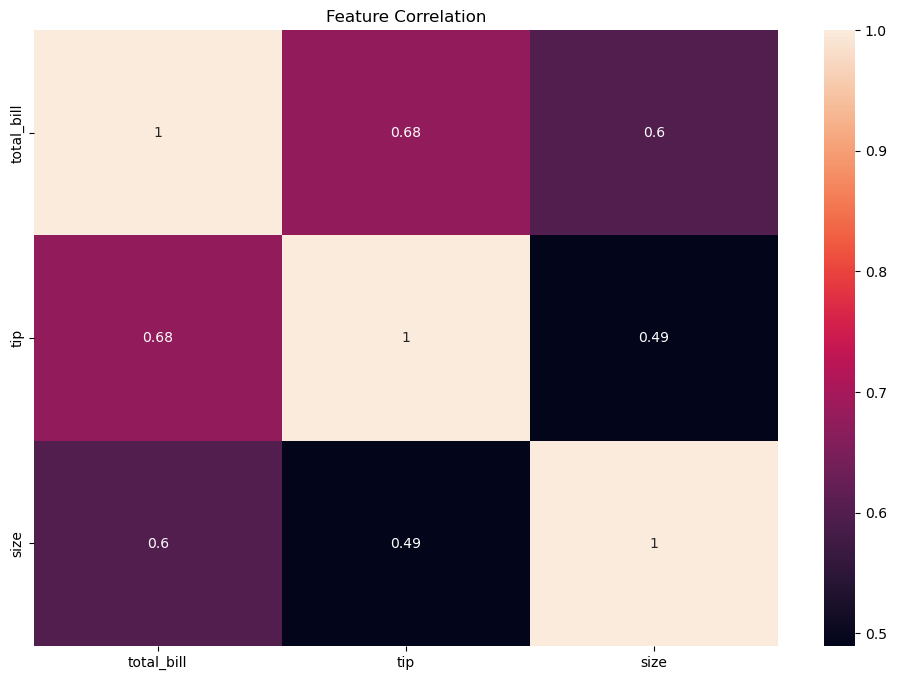

In [17]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.title('Feature Correlation')
plt.show()

<Axes: xlabel='total_bill', ylabel='tip'>

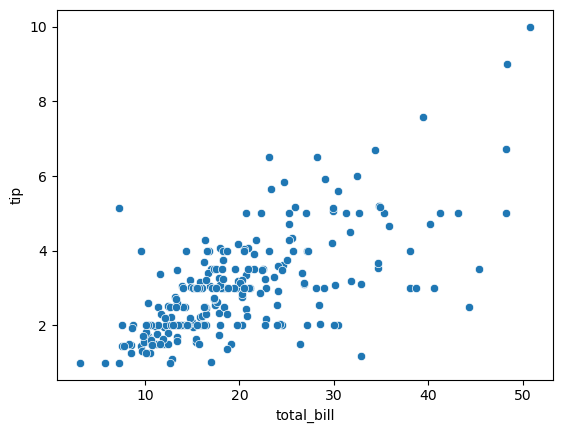

In [18]:
sns.scatterplot(x='total_bill', y='tip', data=df)

<Axes: xlabel='tip', ylabel='Count'>

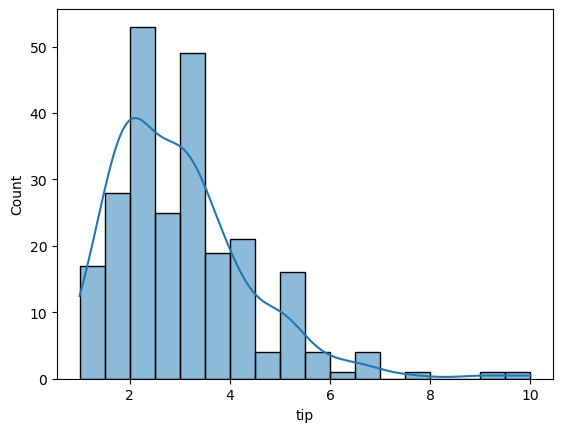

In [19]:
sns.histplot(df['tip'], kde=True)

### Model Selection

In [20]:
lr = LinearRegression()
rf = RandomForestRegressor()

### Model Training

In [21]:
lr.fit(X_train_scaled, y_train)

LinearRegression()

In [22]:
rf.fit(X_train_scaled, y_train)

RandomForestRegressor()

### Model Evaluation

In [23]:
def evalute_model(y_test, y_pred, model_name):
    print(f'--------{model_name}---------')
    print('MAE:', mean_absolute_error(y_test, y_pred))
    print('MSE:', mean_squared_error(y_test, y_pred))
    print('R2 score:', r2_score(y_test, y_pred))


lr_y_pred = lr.predict(X_test_scaled)
rf_y_pred = rf.predict(X_test_scaled)

evalute_model(y_test, lr_y_pred, 'Linear Regression')
evalute_model(y_test, rf_y_pred, 'RandomForest')

--------Linear Regression---------
MAE: 0.697487815358039
MSE: 0.8641994686086172
R2 score: 0.3504334496770184
--------RandomForest---------
MAE: 0.808286885245902
MSE: 1.1112358444262311
R2 score: 0.16475112485160015


### HyperParameter Tuning

In [30]:
param_grid = {
    'n_estimators':[100, 200, 300],
    'max_depth': [None, 10,20],
    'min_samples_split': [2, 3, 5]
}
grid = GridSearchCV(RandomForestRegressor(random_state=42),
                   param_grid,
                   cv=5,
                   scoring='r2')
grid.fit(X_train, y_train)
print('Best parameters:', grid.best_params_)

Best parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}


In [31]:
rf = RandomForestRegressor(max_depth = 10, min_samples_split = 5, n_estimators = 100, random_state=42)

In [32]:
rf.fit(X_train, y_train)

RandomForestRegressor(max_depth=10, min_samples_split=5, random_state=42)

In [33]:
y_pred = rf.predict(X_test)
print('R2 score:', r2_score(y_test, y_pred))

R2 score: 0.16909882077918437


### Deployment

In [34]:
joblib.dump(lr, 'tip_lr_model.pkl')

['tip_lr_model.pkl']

In [42]:
loaded_model = joblib.load('tip_lr_model.pkl')
sample_data = X_test.iloc[0:10]
prediction = lr.predict(sample_data)
print('prediction:', prediction)

prediction: [21.03500053 11.22735753 25.64591263 26.68255853 14.8774134  19.19969994
 28.61968671 14.55205557 16.5713549  17.0053716 ]


C:\Users\Mintesnot\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
